# Shallow topology: Graphlet

Default mode reads the existing results. Set `retrain=True` for a fresh 20-epoch GPU run overwriting the selected variant. Surface geometry starts from the cached baseline CNN. The baseline CNN is frozen; only the classifier is trained.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / "scripts"))
import os
os.environ["DGLBACKEND"] = "pytorch"

import csv
import hashlib
import json
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from model_components import FaceCNN
from model_components import Classifier
from model_utils import graphlet_degree_vectors, orbit_catalog
from data import DATA_DIR, _load_sample, _load_splits
from model_evaluation import evaluate, save_training_summary

from model_components import FaceGraphletBatch, GeometryGraphletClassifier

from model_utils import seed_everything
from model_evaluation import load_cached_run


/Users/yongjun/miniconda3/envs/gnn_report/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
retrain = False
training_mode = "frozen"
max_graphlet_nodes = 4  # 4 (chosen) or 5
graphlet_dim = {4: 15, 5: 73}[max_graphlet_nodes]
run_name = f"graphlet{max_graphlet_nodes}_{training_mode}"
if training_mode != 'frozen':
    raise ValueError('This shallow-topology experiment uses frozen geometry.')
REPORT_DIR = Path.cwd().resolve()
run_dir = REPORT_DIR / 'data' / 'model_runs' / run_name
if not retrain:
    load_cached_run(run_name)  # Verify the supplied cache; never starts training.
    run = {**json.loads((run_dir / 'result.json').read_text()), 'run_dir': str(run_dir)}


/Users/yongjun/miniconda3/envs/gnn_report/lib/python3.11/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


## Optional retraining

In [3]:
if retrain:
    if not torch.cuda.is_available():
        raise RuntimeError('Retraining requires a CUDA GPU. Keep retrain=False to inspect cached results.')
    seed = 0
    deterministic = True
    seed_everything(seed, deterministic=deterministic)
    num_epochs, batch_size, learning_rate = 20, 128, 0.001
    device = torch.device('cuda')
    project_dir = REPORT_DIR
    baseline_checkpoint = REPORT_DIR / 'data/model_runs/baseline/epoch_020/checkpoint.pt'
    checkpoint = torch.load(baseline_checkpoint, map_location='cpu', weights_only=True)
    config = checkpoint['config']
    embedding_dim, hidden_dim = config['embedding_dim'], config['hidden_dim']
    num_classes, in_channels = config['num_classes'], config['in_channels']
    baseline_hash = hashlib.sha256(baseline_checkpoint.read_bytes()).hexdigest()
    cache_dir = REPORT_DIR / 'data' / 'feature_cache'
    import shutil
    if run_dir.exists():
        shutil.rmtree(run_dir)
    run_dir.mkdir(parents=True)



In [4]:
if retrain:
    # Baseline was nn.Sequential(face_cnn, classifier): prefix 0. selects the CNN.
    cnn_state = {key.removeprefix("0."): value
                 for key, value in checkpoint["model_state_dict"].items()
                 if key.startswith("0.")}
    face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
    face_cnn.load_state_dict(cnn_state, strict=True)
    face_cnn.requires_grad_(False)
    face_cnn = face_cnn.to(device).eval()  # used only to prepare frozen-mode embeddings


    def build_model():
        # Initialize the same head first in either mode, under the same seed.
        head = Classifier(embedding_dim + graphlet_dim, hidden_dim, num_classes)
        if training_mode == "frozen":
            return head.to(device)
        with torch.random.fork_rng(devices=[]):
            encoder = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
        encoder.load_state_dict(cnn_state, strict=True)
        encoder.requires_grad_(True)
        return GeometryGraphletClassifier(encoder, head).to(device)


    seed_everything(seed, deterministic=deterministic)
    model = build_model()
    print(model)
    print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))



In [5]:
if retrain:
    def count_metadata(sample_ids, size):
        return dict(cache_version=1, sample_ids=sample_ids, max_graphlet_nodes=size,
                    encoding="exact_induced_orbits_simple_graph_rooted_subset_normalization")


    def metadata_key(metadata):
        return hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:16]


    def load_count_cache(sample_ids, split, size):
        metadata = count_metadata(sample_ids, size)
        path = cache_dir / f"graphlet_counts_{split}_{metadata_key(metadata)}.pt"
        if not path.is_file():
            return None
        cached = torch.load(path, map_location="cpu", weights_only=True)
        if cached["metadata"] != metadata:
            raise ValueError("Graphlet count cache metadata mismatch.")
        return cached["counts"]


    @torch.no_grad()
    def prepare_inputs(split, encode_batch_size=128):
        sample_ids = _load_splits()[split]
        metadata = dict(cache_version=1, baseline_hash=baseline_hash,
                        max_graphlet_nodes=max_graphlet_nodes, training_mode=training_mode,
                        sample_ids=sample_ids, embedding_dim=embedding_dim,
                        in_channels=in_channels, encoding=count_metadata(sample_ids, max_graphlet_nodes)["encoding"])
        cache_path = cache_dir / f"graphlet_inputs_{split}_{metadata_key(metadata)}.pt"
        if cache_path.is_file():
            cached = torch.load(cache_path, map_location="cpu", weights_only=True)
            if cached["metadata"] != metadata:
                raise ValueError("Graphlet input cache metadata mismatch.")
            print("Using cache:", cache_path)
            return cached["samples"], sample_ids

        counts = load_count_cache(sample_ids, split, max_graphlet_nodes)
        if counts is None and max_graphlet_nodes == 4:
            larger_counts = load_count_cache(sample_ids, split, 5)
            if larger_counts is not None:
                counts = [features[:, :15].clone() for features in larger_counts]
        compute_counts = counts is None
        if compute_counts:
            counts = []
        face_cnn.eval()
        samples = []
        for start in tqdm(range(0, len(sample_ids), encode_batch_size), desc=f"Cache graphlets {split}"):
            solids = [_load_sample(sample_id) for sample_id in sample_ids[start:start + encode_batch_size]]
            geometry = None
            if training_mode == "frozen":
                sizes = [solid["graph"].num_nodes() for solid in solids]
                grids = torch.cat([solid["graph"].ndata["x"] for solid in solids])
                grids = grids.permute(0, 3, 1, 2).contiguous().float().to(device)
                geometry = face_cnn(grids).cpu().split(sizes)
            for offset, solid in enumerate(solids):
                if compute_counts:
                    gdv = graphlet_degree_vectors(solid["graph"], max_graphlet_nodes, normalize=True)
                    counts.append(gdv)
                else:
                    gdv = counts[start + offset]
                labels = torch.tensor([face["segment"]["index"] for face in solid["faces"]], dtype=torch.long)
                if training_mode == "frozen":
                    samples.append((torch.cat((geometry[offset], gdv), 1), labels))
                else:
                    grids = solid["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float()
                    samples.append((grids, gdv, labels))
        cache_dir.mkdir(parents=True, exist_ok=True)
        counts_meta = count_metadata(sample_ids, max_graphlet_nodes)
        counts_path = cache_dir / f"graphlet_counts_{split}_{metadata_key(counts_meta)}.pt"
        if not counts_path.is_file():
            temporary = counts_path.with_suffix(".pt.tmp")
            torch.save(dict(metadata=counts_meta, counts=counts), temporary)
            os.replace(temporary, counts_path)
        temporary = cache_path.with_suffix(".pt.tmp")
        torch.save(dict(metadata=metadata, samples=samples), temporary)
        os.replace(temporary, cache_path)
        print("Saved inputs:", cache_path)
        return samples, sample_ids


    train_samples, train_ids = prepare_inputs("train")
    validation_samples, validation_ids = prepare_inputs("validation")



In [6]:
if retrain:
    # Fit preprocessing on training faces only, following the tutorial's StandardScaler.
    train_gdv = torch.cat([sample[0][:, embedding_dim:] if training_mode == "frozen"
                           else sample[1] for sample in train_samples])
    graphlet_mean = train_gdv.mean(0)
    graphlet_scale = train_gdv.std(0, unbiased=False)
    graphlet_scale[graphlet_scale < 1e-8] = 1
    feature_stats_hash = hashlib.sha256(torch.cat((graphlet_mean, graphlet_scale)).numpy().tobytes()).hexdigest()
    del train_gdv


    class FeatureDataset(Dataset):
        def __init__(self, samples):
            self.samples = samples

        def __len__(self):
            return len(self.samples)

        def __getitem__(self, index):
            if training_mode == "joint":
                grids, gdv, labels = self.samples[index]
                return (grids, (gdv - graphlet_mean) / graphlet_scale), labels
            features, labels = self.samples[index]
            features = features.clone()
            features[:, embedding_dim:] = (features[:, embedding_dim:] - graphlet_mean) / graphlet_scale
            return features, labels


    def collate_features(batch):
        inputs, labels = zip(*batch)
        if training_mode == "joint":
            grids, graphlets = zip(*inputs)
            inputs = FaceGraphletBatch(torch.cat(grids), torch.cat(graphlets))
        else:
            inputs = torch.cat(inputs)
        return inputs, torch.cat(labels)


    loader_options = dict(batch_size=batch_size, collate_fn=collate_features,
                          num_workers=0, pin_memory=device.type == "cuda")
    train_loader = DataLoader(FeatureDataset(train_samples), shuffle=True, **loader_options)
    train_evaluation_loader = DataLoader(FeatureDataset(train_samples), shuffle=False, **loader_options)
    validation_loader = DataLoader(FeatureDataset(validation_samples), shuffle=False, **loader_options)
    inputs, labels = next(iter(validation_loader))
    model.eval()
    with torch.no_grad():
        logits = model(inputs.to(device))
    assert logits.shape == (len(labels), num_classes)
    assert torch.isfinite(logits).all()
    print("Maximum graphlet nodes:", max_graphlet_nodes, "Mode:", training_mode,
          "Orbit features:", graphlet_dim, "Logits:", tuple(logits.shape))



In [7]:
if retrain:
    seed_everything(seed, deterministic=deterministic)
    model = build_model()
    use_amp = training_mode == "joint" and device.type == "cuda"
    if use_amp:
        model = model.to(memory_format=torch.channels_last)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    loss_fn = nn.CrossEntropyLoss()
    history, batch_history = [], []
    global_step = 0

    run_config = dict(stage="graphlet", seed=seed, deterministic=deterministic,
                      embedding_dim=embedding_dim, graphlet_dim=graphlet_dim, max_graphlet_nodes=max_graphlet_nodes,
                      feature_stats_hash=feature_stats_hash,
                      hidden_dim=hidden_dim, num_classes=num_classes,
                      learning_rate=learning_rate, batch_size=batch_size,
                      baseline_hash=baseline_hash, train_sample_ids=train_ids,
                      validation_sample_ids=validation_ids, training_mode=training_mode,
                      mixed_precision=use_amp)
    run_dir.mkdir(parents=True, exist_ok=True)


    @torch.no_grad()
    def validation_metrics():
        model.eval()
        loss_total = torch.zeros((), device=device)
        correct_total = torch.zeros((), dtype=torch.long, device=device)
        faces = 0
        for features, labels in validation_loader:
            features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(features)
                loss = loss_fn(logits, labels)
            loss_total += loss * labels.numel()
            correct_total += (logits.argmax(1) == labels).sum()
            faces += labels.numel()
        return loss_total.item() / faces, correct_total.item() / faces


    for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):
        model.train()
        losses, correct, sizes = [], [], []
        for features, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
            features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(features)
                loss = loss_fn(logits, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            losses.append(loss.detach())
            correct.append((logits.detach().argmax(1) == labels).sum())
            sizes.append(labels.numel())

        loss_values = torch.stack(losses).cpu().tolist()
        train_loss = sum(loss * size for loss, size in zip(loss_values, sizes)) / sum(sizes)
        train_accuracy = torch.stack(correct).sum().item() / sum(sizes)
        for batch_index, (batch_loss, count) in enumerate(zip(loss_values, sizes), 1):
            global_step += 1
            batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                      loss=batch_loss, faces=count))
        val_loss, val_accuracy = validation_metrics()
        row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
                   train_accuracy=train_accuracy, validation_loss=val_loss,
                   validation_accuracy=val_accuracy)
        history.append(row)
        with (run_dir / "history.csv").open("w", newline="") as file:
            writer = csv.DictWriter(file, fieldnames=list(row))
            writer.writeheader()
            writer.writerows(history)
        tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
                   f"accuracy {train_accuracy:.2%} | validation loss {val_loss:.4f}, "
                   f"accuracy {val_accuracy:.2%}")
        with (run_dir / "batch_loss.csv").open("w", newline="") as file:
            writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
            writer.writeheader()
            writer.writerows(batch_history)

    checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    torch.save(dict(epoch=num_epochs, config={**run_config, 'num_epochs': num_epochs},
                    model_state_dict=model.state_dict(), history=history, extra=dict(graphlet_mean=graphlet_mean, graphlet_scale=graphlet_scale, baseline_checkpoint=str(baseline_checkpoint), baseline_hash=baseline_hash, face_cnn_state_dict=(model.face_cnn if training_mode == "joint" else face_cnn).state_dict(), train_sample_ids=train_ids, validation_sample_ids=validation_ids)), checkpoint_dir / 'checkpoint.pt')

    final_train_results = evaluate(model, train_evaluation_loader,
                                   None, device=device,
                                   sample_ids=train_ids, split="train")
    save_training_summary(final_train_results, checkpoint_dir / 'train_metrics.json')
    final_validation_results = evaluate(model, validation_loader,
                                        checkpoint_dir / "validation_predictions.pt", device=device,
                                        sample_ids=validation_ids, split="validation")
    print("Final predictions saved to:", checkpoint_dir)

    from model_evaluation import compact_validation_cache
    compact_validation_cache(run_dir, num_epochs)

    from data import LABEL_MAPPING
    names = {}
    for annotation in (DATA_DIR / 'labels').glob('*.json'):
        for face in json.loads(annotation.read_text())['body']['faces']:
            segment = face['segment']
            names[str(segment['index'])] = LABEL_MAPPING[segment['name']]
        if len(names) == 16:
            break
    files = {p.relative_to(run_dir).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
             for p in run_dir.rglob('*') if p.is_file() and p.name != 'result.json'}
    run = dict(final_epoch=num_epochs, class_names=names, files=files, run_dir=str(run_dir))
    (run_dir / 'result.json').write_text(json.dumps(run, indent=2) + '\n')



## Cached training history

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from data import corrected_label

root = Path(run['run_dir'])
final = root / f"epoch_{run['final_epoch']:03d}"
if (root / 'history.csv').exists():
    history = pd.read_csv(root / 'history.csv')
else:
    checkpoint = torch.load(final / 'checkpoint.pt', map_location='cpu', weights_only=True)
    history = pd.DataFrame(checkpoint['history'])

### Loss and accuracy plots

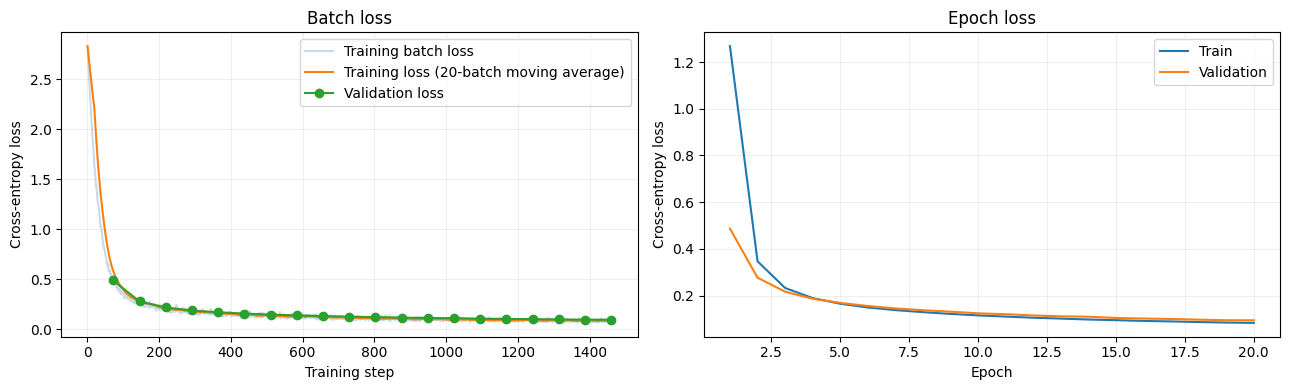

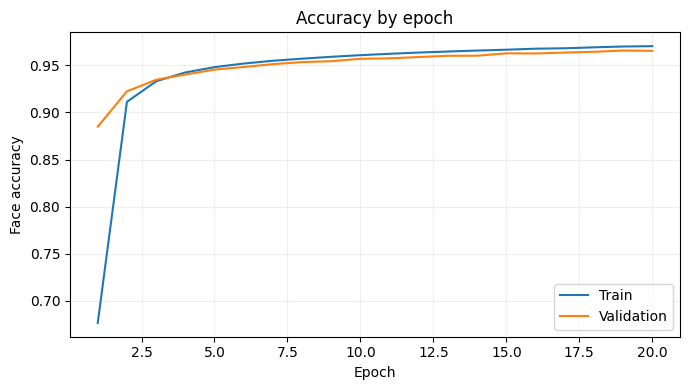

In [9]:
batch_log = pd.read_csv(root / 'batch_loss.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(batch_log['step'], batch_log['loss'], alpha=0.25, label='Training batch loss')
axes[0].plot(batch_log['step'], batch_log['loss'].rolling(20, min_periods=1).mean(),
             label='Training loss (20-batch moving average)')
axes[0].plot(history['step'], history['validation_loss'], marker='o', label='Validation loss')
axes[0].set(xlabel='Training step', ylabel='Cross-entropy loss', title='Batch loss')
for split in ['train', 'validation']:
    axes[1].plot(history['epoch'], history[f'{split}_loss'], label=split.capitalize())
axes[1].set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Epoch loss')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for split in ['train', 'validation']:
    ax.plot(history['epoch'], history[f'{split}_accuracy'], label=split.capitalize())
ax.set(xlabel='Epoch', ylabel='Face accuracy', title='Accuracy by epoch')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Final cached results

Overall mean IoU includes stock. Per-class results use the reviewed names; recall is the fraction of faces of that class classified correctly.

In [10]:
from model_evaluation import read_cached_metrics
summary, per_class = read_cached_metrics(root, run['final_epoch'], run['class_names'])
display(summary.style.format({'faces': '{:,}', 'loss': '{:.4f}', 'accuracy': '{:.2%}', 'mean_iou': '{:.2%}'}))
summary.to_csv(root / 'summary.csv')
per_class.to_csv(root / 'per_class_metrics.csv', index=False)


,faces,loss,accuracy,mean_iou
split,,,,
train,"209,847",0.0825,97.03%,93.28%
validation,"70,255",0.0945,96.55%,92.33%


### Per-class results

In [11]:
for split in ['train', 'validation']:
    print(f"{split.capitalize()} — per-class results")
    table = per_class.loc[per_class['split'] == split].set_index(['class_index', 'class_name'])
    display(table[['support', 'recall', 'precision', 'iou']].style.format(
        {'support': '{:,}', 'recall': '{:.2%}', 'precision': '{:.2%}', 'iou': '{:.2%}'}))

Train — per-class results


,,support,recall,precision,iou
class_index,class_name,,,,
0,chamfer,"2,927",100.00%,99.97%,99.97%
1,triangular_passage,"9,605",97.57%,98.85%,96.48%
2,rectangular_passage,"13,077",93.11%,90.89%,85.16%
3,6sides_passage,"19,859",96.29%,98.46%,94.86%
4,triangular_through_slot,"5,778",99.91%,100.00%,99.91%
5,rectangular_through_slot,"8,508",86.72%,89.68%,78.85%
6,rectangular_through_step,"5,630",91.26%,96.07%,87.98%
7,2sides_through_step,"8,010",99.95%,99.75%,99.70%
8,slanted_through_step,"5,318",99.62%,99.91%,99.53%


Validation — per-class results


,,support,recall,precision,iou
class_index,class_name,,,,
0,chamfer,924,99.68%,99.78%,99.46%
1,triangular_passage,"2,985",97.96%,98.45%,96.47%
2,rectangular_passage,"4,390",91.34%,89.69%,82.66%
3,6sides_passage,"6,804",95.74%,97.90%,93.81%
4,triangular_through_slot,"1,892",99.84%,99.74%,99.58%
5,rectangular_through_slot,"2,883",84.50%,89.17%,76.63%
6,rectangular_through_step,"1,804",91.08%,94.43%,86.43%
7,2sides_through_step,"2,730",99.60%,99.67%,99.27%
8,slanted_through_step,"1,660",99.58%,99.70%,99.28%
